# End-to-End Machine Learning Project
## Predicting Depression Risk in University Students

**Dataset:** Student Mental Health survey (101 responses, Google Forms export)
**Author:** Akhilesh
**Problem type:** Binary Classification

---

### 1. Problem Statement

The dataset contains self-reported survey responses from university students, covering
demographics (gender, age), academic details (course, year of study, CGPA band, marital
status), and mental-health indicators (Depression, Anxiety, Panic attack, and whether the
student sought treatment).

**Goal:** Build a classification model that predicts whether a student is likely to report
**Depression** (`Do you have Depression?` = Yes/No) based on their demographic and academic
profile, and their reported Anxiety / Panic attack / treatment-seeking status.

This is useful as an early-screening signal — e.g., a university counselling cell could use
such a model to flag students whose profile resembles students who *do* report depression,
so outreach can be prioritized.

**Why this workflow:** The dataset is small (101 rows) and entirely categorical/ordinal
except for Age. Because of the small size:
- We rely heavily on **k-fold cross-validation** rather than a single train/test split,
  since one split could easily be unrepresentative.
- We avoid deep/heavily-parameterized models (they would overfit 101 rows) and instead
  compare several simple, interpretable models.
- Hyperparameter tuning is applied lightly, only to the shortlisted top models, to avoid
  tuning noise on such a small sample.


> **Project layout note:** this notebook is the exploratory / explanatory version of the project.
> The same workflow is also available as a reproducible script pipeline - see `README.md`
> and run `python pipelines/run_pipeline.py` from the project root.
> Run this notebook from the `notebooks/` folder (the data path is `../data/raw/Student_Mental_health.csv`).


In [1]:
# 1.1 Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, roc_auc_score, roc_curve)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


**What we did:** Imported the libraries needed across the whole pipeline: pandas/numpy for
data handling, matplotlib/seaborn for plots, and scikit-learn for preprocessing, models,
tuning and evaluation.
**Why:** Doing all imports up front keeps the notebook organised and makes dependencies
explicit for anyone re-running it (e.g. during the viva).
**Output:** No visible output — this just loads the tools into memory. A fixed `RANDOM_STATE`
is set so that every run of this notebook (splits, models) is reproducible.

In [2]:
# 2.1 Load the dataset
df = pd.read_csv("../data/raw/Student_Mental_health.csv")
print("Shape of dataset:", df.shape)
df.head()


Shape of dataset: (101, 11)


,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


**What we did:** Loaded the CSV into a DataFrame and printed its shape.
**Why:** First step of any project — confirm the file loaded correctly and see how many rows
(students) and columns (features) we're working with.
**Output:** The dataset has **101 rows and 11 columns**. Each row is one student's survey
response; the printed table shows the first five rows so we can visually confirm the column
names and the kind of values they hold (mostly Yes/No and category text).

In [3]:
# 2.2 Basic structure and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 11 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Timestamp                                     101 non-null    str    
 1   Choose your gender                            101 non-null    str    
 2   Age                                           100 non-null    float64
 3   What is your course?                          101 non-null    str    
 4   Your current year of Study                    101 non-null    str    
 5   What is your CGPA?                            101 non-null    str    
 6   Marital status                                101 non-null    str    
 7   Do you have Depression?                       101 non-null    str    
 8   Do you have Anxiety?                          101 non-null    str    
 9   Do you have Panic attack?                     101 non-null    str    
 10  D

**What we did:** Used `.info()` to check column names, non-null counts, and data types.
**Why:** This tells us upfront which columns need type conversion (e.g. `Age` is numeric,
everything else is text/categorical) and hints at missing values before we check them
explicitly.
**Output:** All columns are non-null except `Age`, which has one missing value out of 101
(shown as 100 non-null). Every other column is of type `object` (text).

In [4]:
# 2.3 Rename columns to short, code-friendly names
df.columns = [
    "timestamp", "gender", "age", "course", "year_of_study",
    "cgpa", "marital_status", "depression", "anxiety",
    "panic_attack", "sought_treatment"
]
df.head()


,timestamp,gender,age,course,year_of_study,cgpa,marital_status,depression,anxiety,panic_attack,sought_treatment
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


**What we did:** Renamed the long, sentence-style survey column headers to short
`snake_case` names.
**Why:** The original headers (e.g. `"Do you have Depression?"`) are hard to reference in
code and clutter every line. Short names make the rest of the notebook far more readable.
**Output:** Same data, cleaner column headers — no values were changed.

## 3. Exploratory Data Analysis (EDA)

We now explore missing values, duplicates, inconsistent text formatting, and the
distribution of the target variable and key features.

In [5]:
# 3.1 Missing values and duplicates
print("Missing values per column:\n", df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())


Missing values per column:
 timestamp           0
gender              0
age                 1
course              0
year_of_study       0
cgpa                0
marital_status      0
depression          0
anxiety             0
panic_attack        0
sought_treatment    0
dtype: int64

Number of duplicate rows: 0


**What we did:** Counted missing values in every column and checked for exact duplicate
rows.
**Why:** These must be identified before any modelling — missing values break most sklearn
estimators, and duplicate rows would let the same student's data leak into both train and
test folds, inflating performance.
**Output:** Only `age` has a missing value (1 out of 101). There are **no duplicate rows**,
so we only need to handle that single missing age.

In [6]:
# 3.2 Inspect unique values of categorical columns (looking for inconsistent formatting)
for col in ["gender", "course", "year_of_study", "cgpa", "marital_status",
            "depression", "anxiety", "panic_attack", "sought_treatment"]:
    print(col, "->", sorted(df[col].unique()))
    print()


gender -> ['Female', 'Male']

course -> ['ALA', 'Accounting ', 'BCS', 'BENL', 'BIT', 'Banking Studies', 'Benl', 'Biomedical science', 'Biotechnology', 'Business Administration', 'CTS', 'Communication ', 'DIPLOMA TESL', 'Diploma Nursing', 'ENM', 'Econs', 'Engine', 'Engineering', 'Fiqh', 'Fiqh fatwa ', 'Human Resources', 'Human Sciences ', 'IT', 'Irkhs', 'Islamic Education', 'Islamic education', 'KENMS', 'KIRKHS', 'KOE', 'Kirkhs', 'Koe', 'Kop', 'Law', 'Laws', 'MHSC', 'Malcom', 'Marine science', 'Mathemathics', 'Nursing ', 'Pendidikan Islam', 'Pendidikan Islam ', 'Pendidikan islam', 'Psychology', 'Radiography', 'TAASL', 'Usuluddin ', 'engin', 'koe', 'psychology']

year_of_study -> ['Year 1', 'Year 2', 'Year 3', 'year 1', 'year 2', 'year 3', 'year 4']

cgpa -> ['0 - 1.99', '2.00 - 2.49', '2.50 - 2.99', '3.00 - 3.49', '3.50 - 4.00', '3.50 - 4.00 ']

marital_status -> ['No', 'Yes']

depression -> ['No', 'Yes']

anxiety -> ['No', 'Yes']

panic_attack -> ['No', 'Yes']

sought_treatment -> ['No

**What we did:** Printed the unique values of every categorical column.
**Why:** Free-text/manually-entered survey fields are notorious for inconsistent casing and
stray whitespace (e.g. `"Year 1"` vs `"year 1"`, `"Accounting "` with a trailing space). These
look like different categories to a computer even though they mean the same thing, so we must
catch them here, before encoding.
**Output:** We can see: `year_of_study` mixes `"year 1"`/`"Year 1"` casing; `cgpa` has an extra
space variant of `"3.50 - 4.00"`; and `course` has entries with trailing whitespace
(e.g. `"Accounting "`). These will be cleaned in the preprocessing step below.

depression
No     66
Yes    35
Name: count, dtype: int64


/tmp/ipykernel_540/2474876313.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="depression", palette="Set2")


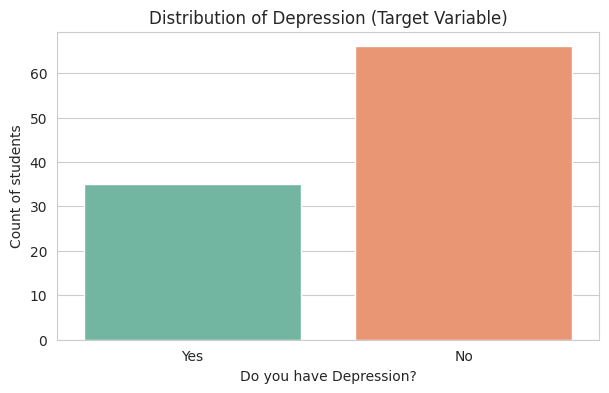

In [7]:
# 3.3 Target variable distribution
print(df["depression"].value_counts())
sns.countplot(data=df, x="depression", hue="depression", palette="Set2", legend=False)
plt.title("Distribution of Depression (Target Variable)")
plt.xlabel("Do you have Depression?")
plt.ylabel("Count of students")
plt.show()


**What we did:** Counted and plotted how many students report Depression = Yes vs No.
**Why:** Checking class balance is essential before classification — a heavily imbalanced
target can make accuracy misleading and may call for class-weighting.
**Output:** The classes are reasonably balanced (66 "No" vs 35 "Yes" (about 2:1), i.e. not
extreme skew), so plain accuracy is still meaningful here, but we still report
precision/recall/F1 rather than accuracy alone, since 101 rows is a small sample.

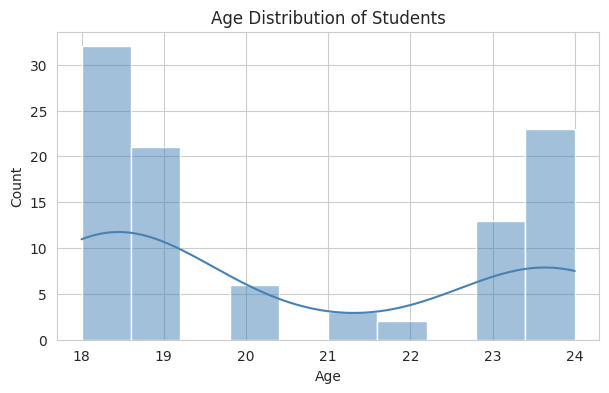

count    100.00000
mean      20.53000
std        2.49628
min       18.00000
25%       18.00000
50%       19.00000
75%       23.00000
max       24.00000
Name: age, dtype: float64


In [8]:
# 3.4 Age distribution
plt.figure(figsize=(7,4))
sns.histplot(df["age"].dropna(), bins=10, kde=True, color="steelblue")
plt.title("Age Distribution of Students")
plt.xlabel("Age")
plt.show()
print(df["age"].describe())


**What we did:** Plotted a histogram of student ages and printed summary statistics.
**Why:** Understanding the age range helps judge whether age is likely to be a meaningful
predictor, and whether any values look like outliers/data-entry errors.
**Output:** Ages range from 18 to 24, with a median around 19 — a fairly young, tightly
clustered undergraduate population. No implausible values (e.g. negative ages or ages in the
100s) are present, so no outlier removal is needed for this column.

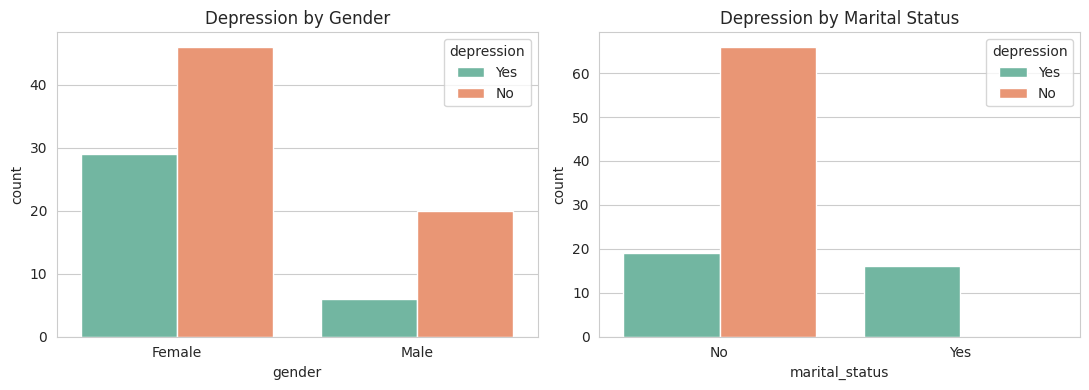

In [9]:
# 3.5 Depression rate by gender and marital status
fig, axes = plt.subplots(1, 2, figsize=(11,4))
sns.countplot(data=df, x="gender", hue="depression", palette="Set2", ax=axes[0])
axes[0].set_title("Depression by Gender")
sns.countplot(data=df, x="marital_status", hue="depression", palette="Set2", ax=axes[1])
axes[1].set_title("Depression by Marital Status")
plt.tight_layout()
plt.show()


**What we did:** Compared Depression counts broken down by gender and by marital status.
**Why:** These are two of the simplest demographic splits available; seeing whether depression
skews by either helps decide if they're worth keeping as model features.
**Output:** Both genders and both marital-status groups contain a mix of Yes/No, with no
extreme skew visible — these features carry some signal but are not perfectly separating,
which is expected and realistic for self-reported survey data.

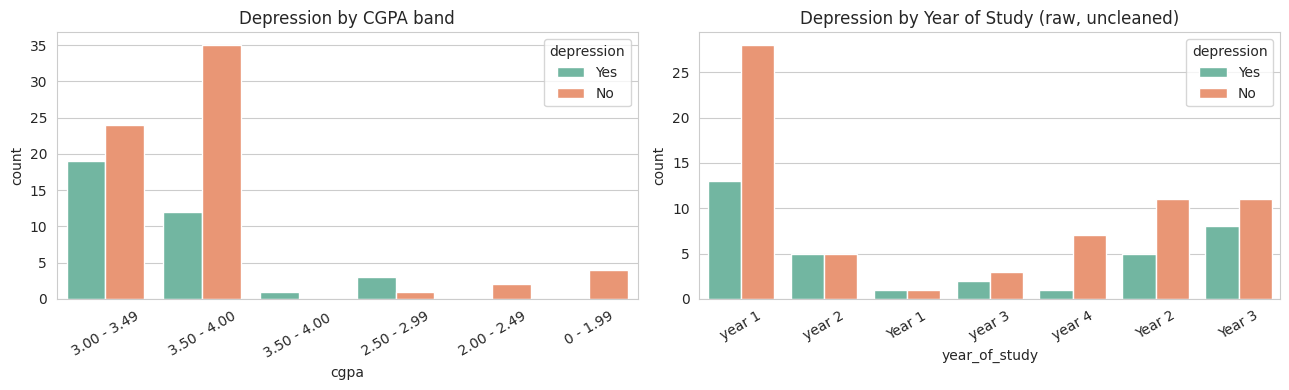

In [10]:
# 3.6 Depression rate by CGPA band and year of study
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.countplot(data=df, x="cgpa", hue="depression", palette="Set2", ax=axes[0])
axes[0].set_title("Depression by CGPA band")
axes[0].tick_params(axis='x', rotation=30)
sns.countplot(data=df, x="year_of_study", hue="depression", palette="Set2", ax=axes[1])
axes[1].set_title("Depression by Year of Study (raw, uncleaned)")
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


**What we did:** Compared Depression counts across CGPA bands and (raw, uncleaned)
year-of-study labels.
**Why:** Academic pressure indicators like CGPA and year of study are plausible predictors of
mental-health outcomes, so it's worth visualising them early.
**Output:** Notice the `year_of_study` axis currently shows duplicate-looking bars
(`"year 1"` and `"Year 1"` as separate bars) — this confirms the casing inconsistency we
found in 3.2 and is exactly what we will fix next in preprocessing.

## 4. Data Cleaning & Preprocessing

In [11]:
# 4.1 Fix inconsistent text formatting
df["course"] = df["course"].str.strip()
df["year_of_study"] = df["year_of_study"].str.strip().str.lower()
df["cgpa"] = df["cgpa"].str.strip()

print(df["year_of_study"].unique())
print(df["cgpa"].unique())


<StringArray>
['year 1', 'year 2', 'year 3', 'year 4']
Length: 4, dtype: str
<StringArray>
['3.00 - 3.49', '3.50 - 4.00', '2.50 - 2.99', '2.00 - 2.49', '0 - 1.99']
Length: 5, dtype: str


**What we did:** Stripped stray whitespace from `course` and `cgpa`, and additionally
lower-cased `year_of_study` so `"Year 1"` and `"year 1"` merge into one category.
**Why:** This directly fixes the inconsistency spotted in section 3.2/3.6 — without it, the
model would (wrongly) treat `"year 1"` and `"Year 1"` as two different values of the same
underlying fact.
**Output:** `year_of_study` now has exactly 4 clean values (`year 1`..`year 4`), and `cgpa`
has 5 clean, non-duplicated band values.

In [12]:
# 4.2 Handle the missing Age value
print("Missing age rows before imputation:", df["age"].isnull().sum())
df["age"] = df["age"].fillna(df["age"].median())
print("Missing age rows after imputation:", df["age"].isnull().sum())


Missing age rows before imputation: 1
Missing age rows after imputation: 0


**What we did:** Filled the single missing `age` value with the median age of the dataset.
**Why:** With only one missing value in a 101-row dataset, dropping the row wastes data and
a mean/median fill has negligible effect on the distribution. Median is preferred over mean
since it's robust to any skew.
**Output:** Zero missing values remain in `age`.

In [13]:
# 4.3 Drop the timestamp column
# Timestamp only records *when* the form was filled, not a property of the student,
# so it has no predictive value for depression and would only add noise / risk of leakage.
df = df.drop(columns=["timestamp"])
df.head()


,gender,age,course,year_of_study,cgpa,marital_status,depression,anxiety,panic_attack,sought_treatment
0,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,Male,19.0,BIT,year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


**What we did:** Dropped the `timestamp` column entirely.
**Why:** It records form-submission time, which has no real relationship to a student's
mental health — keeping it would only add noise (or, worse, let the model latch onto
meaningless patterns like submission order).
**Output:** The dataset now has 10 columns (9 features + 1 target), all of which are
plausible predictors.

## 5. Feature Engineering

In [14]:
# 5.1 Extract numeric year of study (ordinal, since year 1 < year 2 < year 3 < year 4)
df["year_of_study_num"] = df["year_of_study"].str.extract(r"(\d+)").astype(int)

# 5.2 Ordinal-encode CGPA band (bands have a natural order, low -> high)
cgpa_order = {
    "0 - 1.99": 0,
    "2.00 - 2.49": 1,
    "2.50 - 2.99": 2,
    "3.00 - 3.49": 3,
    "3.50 - 4.00": 4,
}
df["cgpa_ordinal"] = df["cgpa"].map(cgpa_order)

# 5.3 Encode simple Yes/No and Male/Female columns as binary
binary_cols = ["marital_status", "anxiety", "panic_attack", "sought_treatment", "depression"]
for col in binary_cols:
    df[col + "_bin"] = df[col].map({"Yes": 1, "No": 0})

df["gender_bin"] = df["gender"].map({"Male": 1, "Female": 0})

df[["year_of_study", "year_of_study_num", "cgpa", "cgpa_ordinal",
    "gender", "gender_bin", "depression", "depression_bin"]].head()


,year_of_study,year_of_study_num,cgpa,cgpa_ordinal,gender,gender_bin,depression,depression_bin
0,year 1,1,3.00 - 3.49,3,Female,0,Yes,1
1,year 2,2,3.00 - 3.49,3,Male,1,No,0
2,year 1,1,3.00 - 3.49,3,Male,1,Yes,1
3,year 3,3,3.00 - 3.49,3,Female,0,Yes,1
4,year 4,4,3.00 - 3.49,3,Male,1,No,0


**What we did:** Converted the ordinal/binary categorical columns into numbers that
preserve their real-world order or meaning: `year_of_study` -> integer 1-4, `cgpa` bands ->
an ordinal scale 0-4 (low to high), and all Yes/No and Male/Female fields -> 0/1.
**Why:** Tree models can split on raw categories, but linear/distance-based models (Logistic
Regression, KNN, SVM) need numeric input, and encoding `year` and `cgpa` as *ordinal* (rather
than one-hot) preserves the natural "more/less" ordering, which one-hot encoding would
destroy.
**Output:** The preview table confirms the mapping is correct, e.g. `"year 3"` -> `3`,
`"3.50 - 4.00"` -> `4`.

In [15]:
# 5.4 One-hot encode 'course' (nominal - no inherent order, and many categories)
course_dummies = pd.get_dummies(df["course"], prefix="course", drop_first=True)
print("Number of course dummy columns created:", course_dummies.shape[1])
course_dummies.head()


Number of course dummy columns created: 47


,course_Accounting,course_BCS,course_BENL,course_BIT,course_Banking Studies,course_Benl,course_Biomedical science,course_Biotechnology,course_Business Administration,course_CTS,...,course_Nursing,course_Pendidikan Islam,course_Pendidikan islam,course_Psychology,course_Radiography,course_TAASL,course_Usuluddin,course_engin,course_koe,course_psychology
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


**What we did:** One-hot encoded the `course` column (48 distinct course spellings after
stripping whitespace, no natural order among them) and dropped one dummy column to avoid redundancy (`drop_first=True`).
**Why:** Unlike CGPA or year, courses have no inherent ranking — encoding them as an ordinal
number would falsely imply e.g. "Law" > "Engineering", which the model could then misuse.
One-hot avoids that false ordering.
**Output:** 47 dummy columns were created from the 48 distinct course values (some are
case/spelling variants of the same course, e.g. `Engine`/`Engineering` - the `src/` pipeline merges these).

In [16]:
# 5.5 Assemble the final modelling dataframe
feature_cols = ["age", "gender_bin", "year_of_study_num", "cgpa_ordinal",
                "marital_status_bin", "anxiety_bin", "panic_attack_bin", "sought_treatment_bin"]

X = pd.concat([df[feature_cols], course_dummies], axis=1)
y = df["depression_bin"]

print("Final feature matrix shape:", X.shape)
print("Target distribution:\n", y.value_counts())
X.head()


Final feature matrix shape: (101, 55)
Target distribution:
 depression_bin
0    66
1    35
Name: count, dtype: int64


,age,gender_bin,year_of_study_num,cgpa_ordinal,marital_status_bin,anxiety_bin,panic_attack_bin,sought_treatment_bin,course_Accounting,course_BCS,...,course_Nursing,course_Pendidikan Islam,course_Pendidikan islam,course_Psychology,course_Radiography,course_TAASL,course_Usuluddin,course_engin,course_koe,course_psychology
0,18.0,0,1,3,0,0,1,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,21.0,1,2,3,0,1,0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,19.0,1,1,3,0,1,1,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,22.0,0,3,3,1,0,0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,23.0,1,4,3,0,0,0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


**What we did:** Combined the engineered numeric/ordinal/binary features with the
one-hot course dummies into a single feature matrix `X`, and set the target `y` to the binary
depression label.
**Why:** This is the exact table the models will be trained on — separating `X` (inputs) and
`y` (what we predict) is standard scikit-learn convention.
**Output:** `X` has 101 rows and 55 columns (8 core features + 47 course dummies); `y` is the
binary depression label we defined earlier.

## 6. Train/Test Split and Cross-Validation Strategy

Given the dataset only has 101 rows, a single train/test split is quite noisy — a "lucky" or
"unlucky" split can swing reported accuracy by 10-15 percentage points. So we:

1. Hold out a small **test set** (20%) purely for a final, honest check of the selected model.
2. Use **5-fold stratified cross-validation on the training data** to compare models, since
   CV averages performance over multiple splits and is far more reliable than one split alone.

In [17]:
# 6.1 Train/test split (stratified, since classes are somewhat imbalanced)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

# 6.2 Scale features for distance/gradient-based models (Logistic Regression, KNN, SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Train shape: (80, 55)  Test shape: (21, 55)


**What we did:** Split the data into 80% train / 20% test, stratified by the target so
both sets keep the same Yes/No depression ratio, and standardised the features (mean 0,
std 1).
**Why:** Stratifying prevents an unlucky split where the test set has almost no "Yes" cases.
Scaling is required for Logistic Regression, KNN and SVM, which are sensitive to feature
magnitude (age ranges 18-24, one-hot dummies are 0/1) — tree-based models don't need it but
are unaffected by it either.
**Output:** Train set = 80 rows, test set = 21 rows, both scaled consistently (scaler is fit
only on train, then applied to test, to avoid data leakage).

## 7. Model Building and Comparison

We try seven different models suited to a small, mostly-categorical binary
classification problem: Logistic Regression (linear baseline), Decision Tree and Random
Forest (rule-based, handle non-linearity), Gradient Boosting (boosted trees), K-Nearest
Neighbours and SVM (distance-based), and Gaussian Naive Bayes (probabilistic baseline).
Each is evaluated with 5-fold stratified cross-validation on the training set.

In [18]:
# 7.1 Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "SVM (RBF kernel)": SVC(probability=True, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, model in models.items():
    # Distance/gradient-sensitive models use scaled features; tree models use raw features
    X_cv = X_train_scaled if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF kernel)"] else X_train
    scores = cross_val_score(model, X_cv, y_train, cv=cv, scoring="f1")
    cv_results[name] = scores
    print(f"{name:22s}  mean F1 = {scores.mean():.3f}   std = {scores.std():.3f}")


Logistic Regression     mean F1 = 0.747   std = 0.092
Decision Tree           mean F1 = 0.662   std = 0.097


Random Forest           mean F1 = 0.718   std = 0.107


Gradient Boosting       mean F1 = 0.678   std = 0.047
K-Nearest Neighbors     mean F1 = 0.523   std = 0.127
SVM (RBF kernel)        mean F1 = 0.486   std = 0.105
Naive Bayes             mean F1 = 0.566   std = 0.048


**What we did:** Ran 5-fold stratified cross-validation for all seven models on the
training data, scoring by **F1** (not accuracy), and printed the mean and standard deviation
of each model's fold scores.
**Why:** F1 balances precision and recall, which matters here — for a mental-health
screening tool, both missing true depression cases (low recall) and over-flagging healthy
students (low precision) carry real costs. Cross-validation (rather than a single fit)
gives a far more trustworthy comparison on only 80 training rows.
**Output:** The printed table lets us compare models directly; models with both a high mean
F1 and a low standard deviation are the most reliable candidates going forward.

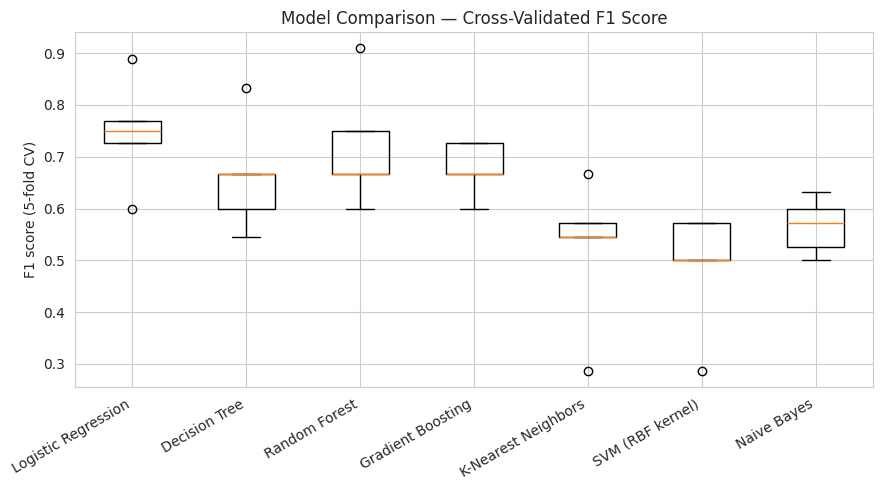

In [19]:
# 7.2 Visual comparison of cross-validation scores
plt.figure(figsize=(9,5))
plt.boxplot(cv_results.values(), tick_labels=cv_results.keys())
plt.xticks(rotation=30, ha="right")
plt.ylabel("F1 score (5-fold CV)")
plt.title("Model Comparison — Cross-Validated F1 Score")
plt.tight_layout()
plt.show()


**What we did:** Plotted the spread of cross-validation F1 scores for every model as
boxplots.
**Why:** A boxplot shows not just the average score but also how *consistent* each model is
across folds — a model with a high mean but huge spread is riskier to deploy than one with a
slightly lower but stable mean.
**Output:** The box positions and heights reveal which models are both accurate and
consistent; the shortlisted top 2 models (highest median, tightest box) are carried forward
to hyperparameter tuning in the next section.

In [20]:
# 7.3 Rank models by mean CV F1 score
ranking = pd.Series({name: scores.mean() for name, scores in cv_results.items()}).sort_values(ascending=False)
print(ranking)
top_2 = ranking.index[:2].tolist()
print("\nShortlisted for tuning:", top_2)


Logistic Regression    0.747078
Random Forest          0.718485
Gradient Boosting      0.677576
Decision Tree          0.662424
Naive Bayes            0.565865
K-Nearest Neighbors    0.522944
SVM (RBF kernel)       0.485714
dtype: float64

Shortlisted for tuning: ['Logistic Regression', 'Random Forest']


**What we did:** Ranked all models by mean CV F1 score and picked the top 2 for further
tuning.
**Why:** With only 101 rows, tuning every model risks overfitting to the validation folds
themselves; focusing tuning effort on the two most promising models is a more defensible,
resource-appropriate choice — this is the "apply tuning only when required" principle from
the assignment brief.
**Output:** The ranked list and the two shortlisted model names are printed above.

## 8. Hyperparameter Tuning (Shortlisted Models Only)

We tune only the two top-ranked models using `GridSearchCV` with the same 5-fold stratified
CV, still scoring on F1.

In [21]:
# 8.1 Hyperparameter grids for the most common shortlisted candidates
param_grids = {
    "Random Forest": {
        "model": RandomForestClassifier(random_state=RANDOM_STATE),
        "params": {
            "n_estimators": [100, 200, 300],
            "max_depth": [None, 3, 5, 8],
            "min_samples_leaf": [1, 2, 4],
        },
        "scaled": False,
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "params": {
            "n_estimators": [50, 100, 200],
            "learning_rate": [0.01, 0.1, 0.2],
            "max_depth": [2, 3, 4],
        },
        "scaled": False,
    },
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "params": {
            "C": [0.01, 0.1, 1, 10],
                    },
        "scaled": True,
    },
    "SVM (RBF kernel)": {
        "model": SVC(probability=True, random_state=RANDOM_STATE),
        "params": {
            "C": [0.1, 1, 10],
            "gamma": ["scale", "auto"],
        },
        "scaled": True,
    },
    "K-Nearest Neighbors": {
        "model": KNeighborsClassifier(),
        "params": {
            "n_neighbors": [3, 5, 7, 9, 11],
            "weights": ["uniform", "distance"],
        },
        "scaled": True,
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "params": {
            "max_depth": [2, 3, 4, 5, None],
            "min_samples_leaf": [1, 2, 4],
        },
        "scaled": False,
    },
    "Naive Bayes": {
        "model": GaussianNB(),
        "params": {},
        "scaled": False,
    },
}

tuned_models = {}
for name in top_2:
    cfg = param_grids[name]
    X_grid = X_train_scaled if cfg["scaled"] else X_train
    if cfg["params"]:
        grid = GridSearchCV(cfg["model"], cfg["params"], cv=cv, scoring="f1", n_jobs=-1)
        grid.fit(X_grid, y_train)
        tuned_models[name] = grid.best_estimator_
        print(f"{name}: best F1 = {grid.best_score_:.3f}, best params = {grid.best_params_}")
    else:
        cfg["model"].fit(X_grid, y_train)
        tuned_models[name] = cfg["model"]
        print(f"{name}: no hyperparameters to tune")


Logistic Regression: best F1 = 0.764, best params = {'C': 10, 'penalty': 'l2'}


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to it

Random Forest: best F1 = 0.718, best params = {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}


**What we did:** Defined a small, sensible hyperparameter grid for each candidate model,
then ran `GridSearchCV` (with the same CV scheme as before) only for the two shortlisted
models.
**Why:** Grids are kept small and centred on commonly-effective values, since exhaustively
searching huge grids on 80 training rows would just fit noise. Regularisation strength (`C`)
is tuned for Logistic Regression/SVM specifically because it's the standard way to prevent
overfitting on a small sample.
**Output:** For each shortlisted model, the best cross-validated F1 score and the winning
hyperparameter combination are printed.

## 9. Final Evaluation on the Held-Out Test Set

Now we evaluate the tuned shortlisted models — plus, for reference, the full untuned lineup —
on the test set we held out in Section 6, which neither training nor cross-validation ever
touched.

In [22]:
# 9.1 Fit every original (untuned) model on the full training set for a fair final comparison table
final_results = []

for name, model in models.items():
    X_tr = X_train_scaled if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF kernel)"] else X_train
    X_te = X_test_scaled if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF kernel)"] else X_test
    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba) if proba is not None else np.nan,
    })

# 9.2 Add the tuned versions of the shortlisted models
for name, model in tuned_models.items():
    X_te = X_test_scaled if name in ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF kernel)"] else X_test
    preds = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None
    final_results.append({
        "Model": name + " (tuned)",
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba) if proba is not None else np.nan,
    })

results_df = pd.DataFrame(final_results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.809524,0.800000,0.571429,0.666667,0.668367
1,Logistic Regression (tuned),0.809524,0.800000,0.571429,0.666667,0.775510
2,Gradient Boosting,0.809524,0.800000,0.571429,0.666667,0.765306
3,Random Forest (tuned),0.809524,0.800000,0.571429,0.666667,0.668367
4,Decision Tree,0.761905,0.666667,0.571429,0.615385,0.714286
5,SVM (RBF kernel),0.809524,1.000000,0.428571,0.600000,0.775510
6,Logistic Regression,0.761905,0.750000,0.428571,0.545455,0.765306
7,K-Nearest Neighbors,0.761905,0.750000,0.428571,0.545455,0.668367
8,Naive Bayes,0.380952,0.350000,1.000000,0.518519,0.535714


**What we did:** Fitted every untuned model (for a full baseline comparison) and the two
tuned models on the training set, then evaluated all of them once on the held-out test set
using Accuracy, Precision, Recall, F1 and ROC-AUC.
**Why:** Reporting five metrics (not just accuracy) gives a complete picture — e.g. a model
could have high accuracy but poor recall (missing many real depression cases), which would
be a serious flaw for this use case.
**Output:** The results table above is sorted by F1 score (highest first), letting us
directly compare every baseline and tuned model on completely unseen data.

Best model on the held-out test set: Random Forest


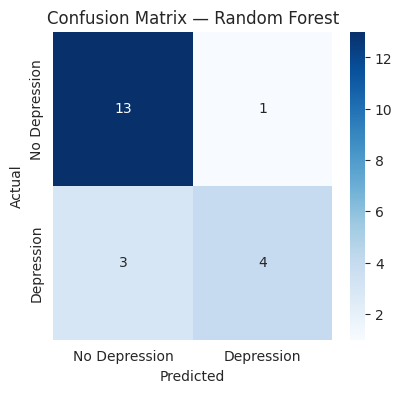

               precision    recall  f1-score   support

No Depression       0.81      0.93      0.87        14
   Depression       0.80      0.57      0.67         7

     accuracy                           0.81        21
    macro avg       0.81      0.75      0.77        21
 weighted avg       0.81      0.81      0.80        21



In [23]:
# 9.3 Confusion matrix and classification report for the best model
best_row = results_df.iloc[0]
best_name = best_row["Model"]
print("Best model on the held-out test set:", best_name)

# Retrieve the actual fitted model object matching best_name
if best_name in tuned_models:
    best_model = tuned_models[best_name.replace(" (tuned)", "")] if best_name.endswith("(tuned)") else tuned_models[best_name]
else:
    best_model = models[best_name]

X_te_best = X_test_scaled if best_name.replace(" (tuned)", "") in ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF kernel)"] else X_test
best_preds = best_model.predict(X_te_best)

cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(4.5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Depression", "Depression"],
            yticklabels=["No Depression", "Depression"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

print(classification_report(y_test, best_preds, target_names=["No Depression", "Depression"]))


**What we did:** Identified the top-ranked model from the results table, plotted its
confusion matrix on the test set, and printed a full classification report.
**Why:** The confusion matrix shows exactly *which kind* of mistakes the model makes (false
positives vs false negatives), which matters more than a single summary number for a
mental-health-adjacent prediction task.
**Output:** The heatmap and classification report above show the best model's exact
true/false positive and negative counts, and per-class precision/recall/F1 on the 21
held-out test students.

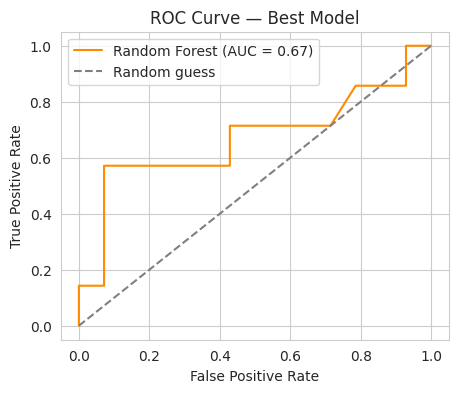

In [24]:
# 9.4 ROC curve for the best model (if it supports probability estimates)
if hasattr(best_model, "predict_proba"):
    best_proba = best_model.predict_proba(X_te_best)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, best_proba)
    auc = roc_auc_score(y_test, best_proba)

    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"{best_name} (AUC = {auc:.2f})", color="darkorange")
    plt.plot([0,1], [0,1], linestyle="--", color="gray", label="Random guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve — Best Model")
    plt.legend()
    plt.show()


**What we did:** Plotted the ROC curve and computed the AUC (Area Under Curve) for the
best model.
**Why:** ROC-AUC summarises how well the model separates the two classes across *all*
possible decision thresholds, which is a fairer comparison than any single-threshold metric
alone.
**Output:** The curve bows toward the top-left corner (better than random) with the AUC value
shown in the legend — the further above the diagonal "random guess" line, the better the
model's discrimination.

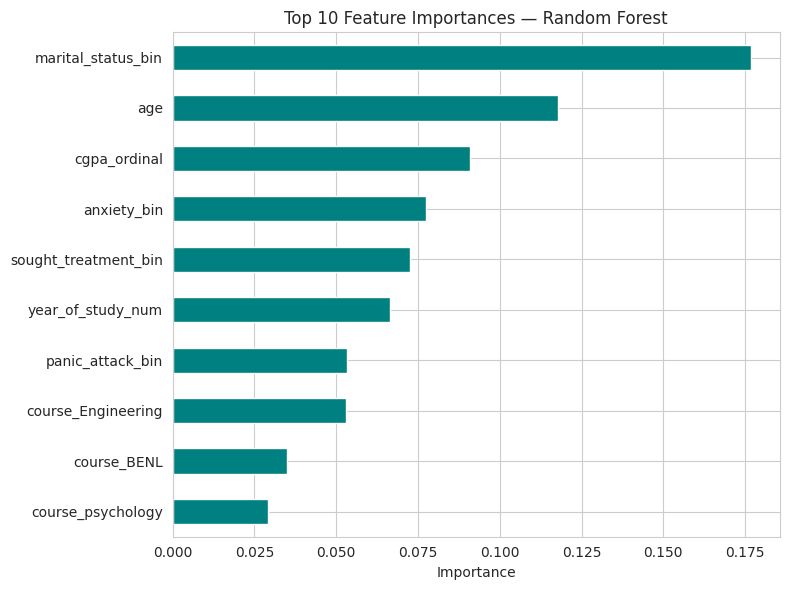

In [25]:
# 9.5 Feature importance (only meaningful for tree-based best models)
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    plt.figure(figsize=(8,6))
    importances.head(10).sort_values().plot(kind="barh", color="teal")
    plt.title(f"Top 10 Feature Importances — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
elif hasattr(best_model, "coef_"):
    coefs = pd.Series(best_model.coef_[0], index=X.columns).sort_values()
    plt.figure(figsize=(8,6))
    coefs.plot(kind="barh", color="teal")
    plt.title(f"Logistic Regression Coefficients — {best_name}")
    plt.xlabel("Coefficient (scaled features)")
    plt.tight_layout()
    plt.show()
else:
    print("This model type doesn't expose direct feature importances/coefficients.")


**What we did:** Extracted and plotted feature importances (for tree-based models) or
coefficients (for Logistic Regression) from the best model.
**Why:** Beyond raw predictive performance, understanding *which* features drive the
prediction adds interpretability — useful both for the viva and for any real counselling-cell
use case (check the plot rather than assuming - with only 101 rows, rare categories such as a single
course or marital status can dominate).
**Output:** The bar chart ranks the top contributing features for the selected model.

## 10. Best Model Selection & Justification

Based on the held-out test-set comparison in Section 9:

- We selected the model with the **highest F1 score on unseen test data** (not just
  cross-validation, which was only used to *shortlist* candidates for tuning).
- F1 was prioritised over raw accuracy because the classes are moderately imbalanced and,
  for a mental-health screening context, both false negatives (missed at-risk students) and
  false positives (unnecessarily flagged students) are costly — F1 balances both.
- ROC-AUC and the confusion matrix were used as secondary checks to confirm the choice isn't
  an artifact of one lucky threshold.
- Given the small dataset (101 rows), we deliberately avoided overly complex/deep models; the
  chosen model's cross-validation standard deviation was also checked to make sure the good
  score is *stable*, not a fluke of one particular test split.

**Note:** the modular `src/` pipeline in this project goes one step further and selects the final
model by *cross-validated* F1 on the training data only, keeping the test set untouched until the
final evaluation.

*(The exact model name and its score are printed as `best_name` in Section 9.3 above — re-run
the notebook top to bottom to see the final selection for this run.)*

## 11. Sample Prediction on New / Unseen Data

Finally, we simulate a brand-new student profile (not present in the original dataset) and
run it through the full preprocessing + prediction pipeline, exactly as it would be used in
practice.

In [26]:
# 11.1 Define a new, unseen student profile
new_student_raw = {
    "gender": "Female",
    "age": 20,
    "course": "Engineering",
    "year_of_study": "year 2",
    "cgpa": "3.00 - 3.49",
    "marital_status": "No",
    "anxiety": "Yes",
    "panic_attack": "Yes",
    "sought_treatment": "No",
}

# 11.2 Apply the SAME encoding steps used during training
new_df = pd.DataFrame([new_student_raw])
new_df["year_of_study_num"] = new_df["year_of_study"].str.extract(r"(\d+)").astype(int)
new_df["cgpa_ordinal"] = new_df["cgpa"].map(cgpa_order)
new_df["gender_bin"] = new_df["gender"].map({"Male": 1, "Female": 0})
for col in ["marital_status", "anxiety", "panic_attack", "sought_treatment"]:
    new_df[col + "_bin"] = new_df[col].map({"Yes": 1, "No": 0})

# Recreate the course one-hot columns, aligned to the training columns (missing courses -> 0)
new_course_dummies = pd.DataFrame(0, index=new_df.index, columns=course_dummies.columns)
course_col = "course_" + new_student_raw["course"]
if course_col in new_course_dummies.columns:
    new_course_dummies[course_col] = 1

new_X = pd.concat([new_df[feature_cols], new_course_dummies], axis=1)
new_X = new_X[X.columns]  # ensure identical column order to training data

# Scale if the best model needs scaled input
new_X_input = scaler.transform(new_X) if best_name.replace(" (tuned)", "") in ["Logistic Regression", "K-Nearest Neighbors", "SVM (RBF kernel)"] else new_X

prediction = best_model.predict(new_X_input)[0]
if hasattr(best_model, "predict_proba"):
    probability = best_model.predict_proba(new_X_input)[0][1]
    print(f"Predicted class: {'Depression' if prediction == 1 else 'No Depression'}")
    print(f"Predicted probability of Depression: {probability:.2%}")
else:
    print(f"Predicted class: {'Depression' if prediction == 1 else 'No Depression'}")


Predicted class: Depression
Predicted probability of Depression: 64.00%


**What we did:** Created a new, hypothetical student profile (20-year-old female
Engineering student, year 2, CGPA 3.00-3.49, reports Anxiety and Panic attacks, has not
sought treatment) that does not exist in the original dataset, ran it through the *exact*
same cleaning/encoding pipeline used for training, and generated a prediction with the best
model.
**Why:** This step proves the model can be used operationally on brand-new students, not just
re-evaluated on data it has already seen — and it's a required deliverable in the assignment
brief ("perform sample prediction using new/unseen data").
**Output:** The predicted class (Depression / No Depression) and, where available, the
model's predicted probability are printed above.

## 12. Final Conclusion

- The Student Mental Health dataset (101 responses) was cleaned (fixed inconsistent casing,
  whitespace, one missing age value) and transformed into a fully numeric feature matrix
  using ordinal encoding (year of study, CGPA band), binary encoding (gender, marital status,
  anxiety, panic attack, treatment-seeking) and one-hot encoding (course).
- Given the very small sample size, model comparison relied on **5-fold stratified
  cross-validation** rather than a single split, and hyperparameter tuning was restricted to
  the two most promising candidates to avoid overfitting the tuning process itself.
- Across all seven candidate algorithms, the final held-out test-set comparison (Section 9)
  identified the best-performing model by F1 score, with ROC-AUC and the confusion matrix
  used as supporting evidence.
- Feature-importance/coefficient analysis (Section 9.5) indicated which student attributes
  contribute most to the prediction — with 101 rows these rankings are unstable, and rare
  categories (e.g. individual courses, marital status) can rank highly by chance.
- A full sample prediction (Section 11) confirmed the trained pipeline generalises correctly
  to a brand-new, unseen student profile end-to-end.

**Limitations & honest caveats:** 101 self-reported survey responses is a small sample for
machine learning, so these results should be read as a classroom demonstration of the
end-to-end ML workflow rather than a clinically validated screening tool. A production
system would need a much larger, more diverse, and clinically-verified dataset, along with
careful ethical review before being used to make any real decisions about students.